In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

KeyboardInterrupt: 

In [ ]:
def evaluate_probabilities(prob, true, model_name):
    """
    Evaluate probability predictions of a model_name with a number of different metrics
    """

    logloss = log_loss(y_true = true, y_proba = prob)
    roc_score  = roc_auc_score(y_true = true, y_score= prob)
    brier_score = brier_score_loss(y_true = true, y_proba = prob)

    print(f"Scores for the model: {model_name}: ")
    print(f"\nCross-entropy: {logloss}")
    print(f"\nAUC: {roc_score}")
    print(f"\nBrier Score: {brier_score}")

In [ ]:
df = pl.read_parquet("../data/processed_demos/tick_dataset.parquet")
df.head(10)

round_num,tick,event_type,ct_death,t_death,freeze_end_tick,ct_win,ct_equip_value,t_equip_value,equip_value_ratio,seconds_elapsed,ct_alive,t_alive,is_plant_event,is_bomb_planted,plant_tick,seconds_since_plant,match_id
i32,i32,str,i32,i32,i32,i32,i32,i32,f64,f64,i32,i32,i32,i32,i32,f64,str
1,5462,"""kill""",1,0,1380,1,4800,4200,1.142585,63.78125,4,5,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,5752,"""kill""",0,1,1380,1,4800,4200,1.142585,68.3125,4,4,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,6222,"""kill""",0,1,1380,1,4800,4200,1.142585,75.65625,4,3,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,6342,"""kill""",0,1,1380,1,4800,4200,1.142585,77.53125,4,2,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,6350,"""kill""",1,0,1380,1,4800,4200,1.142585,77.65625,3,2,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,6554,"""kill""",0,1,1380,1,4800,4200,1.142585,80.84375,3,1,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,6771,"""kill""",1,0,1380,1,4800,4200,1.142585,84.234375,2,1,0,0,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,7157,"""bomb_planted""",0,0,1380,1,4800,4200,1.142585,90.265625,2,1,1,1,7157,0.0,"""aurora-vs-vitality-m1-anubis"""
1,7330,"""kill""",0,1,1380,1,4800,4200,1.142585,92.96875,2,0,0,1,7157,2.703125,"""aurora-vs-vitality-m1-anubis"""


In [ ]:
features = ["ct_alive", "t_alive", "ct_equip_value", "t_equip_value", "equip_value_ratio", "seconds_elapsed", "is_bomb_planted", "seconds_since_plant"]
X = df[features].to_numpy()
Y = df["ct_win"].to_numpy()

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42, stratify=Y)

In [ ]:
#scaler = StandardScaler()
#X_train_scaled = scaler.fit_transform(X_train)
#X_test_scaled = scaler.transform(X_test)

In [ ]:
log_reg = LogisticRegression(random_state = 42)
log_reg.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [ ]:
xgb = XGBClassifier(n_estimators=100, max_depth = 5, learning_rate = 0.1, objective="binary:logistic")
xgb.fit(X_train, Y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
pca = PCA(n_components = 5, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
xgb_pca = XGBClassifier(n_estimators=100, max_depth = 5, learning_rate = 0.1, objective="binary:logistic")
xgb_pca.fit(X_train_pca, Y_train)

print("Explained Variance Ratio per Component:", pca.explained_variance_ratio_)
print("Total Variance Retained:", sum(pca.explained_variance_ratio_))

Explained Variance Ratio per Component: [0.30494198 0.19896678 0.16197654 0.11063536 0.0782723 ]
Total Variance Retained: 0.8547929572949937


In [ ]:
mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", solver="adam", random_state=42, learning_rate = "adaptive", max_iter=2000)
mlp.fit(X_train, Y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'adaptive'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [ ]:
Y_pred_logreg_prob = log_reg.predict_proba(X_test)[:, 1]
Y_pred_xgb_prob = xgb.predict_proba(X_test)[:, 1]
Y_pred_mlp_prob = mlp.predict_proba(X_test)[:, 1]

X_test_pca = pca.transform(X_test)
Y_pred_xgbpca_prob = xgb_pca.predict_proba(X_test_pca)[:, 1]


In [ ]:
evaluate_probabilities(prob=Y_pred_logreg_prob, true=Y_test, model_name="Logistic Regression")

Scores for the model: Logistic Regression: 

Cross-entropy: 0.3738690371326487

AUC: 0.9105714410062236

Brier Score: 0.12202816899692602


In [ ]:
evaluate_probabilities(prob=Y_pred_xgb_prob, true=Y_test, model_name="XGBoost")

Scores for the model: XGBoost: 

Cross-entropy: 0.22678546607494354

AUC: 0.9719632676154416

Brier Score: 0.06839839369058609


In [ ]:
evaluate_probabilities(prob=Y_pred_xgbpca_prob, true=Y_test, model_name="XGBoost - PCA")

Scores for the model: XGBoost - PCA: 

Cross-entropy: 0.3811553716659546

AUC: 0.9087043565304436

Brier Score: 0.12496279925107956


In [ ]:
evaluate_probabilities(prob=Y_pred_mlp_prob, true=Y_test, model_name="Multi-Layer Perceptron")

Scores for the model: Multi-Layer Perceptron: 

Cross-entropy: 0.3696739399123477

AUC: 0.9153675414544981

Brier Score: 0.12010902671271874


Visualizing the tick-by-tick win probability during a live round

In [ ]:
sample_round = df.filter(
    (pl.col("match_id") == df["match_id"][0]) & (pl.col("round_num") == 1)
).sort("seconds_elapsed")

In [ ]:
#X_sample = sample_round.select(features).to_numpy()
#X_sample_scaled = scaler.transform(X_sample)

In [ ]:
ct_win_probs_xgb = xgb.predict_proba(X_sample)[:, 1]
ct_win_probs_logreg = log_reg.predict_proba(X_sample)[:, 1]
ct_win_probs_mlp = mlp.predict_proba(X_sample)[:, 1]
time_axis = sample_round["seconds_elapsed"].to_numpy()

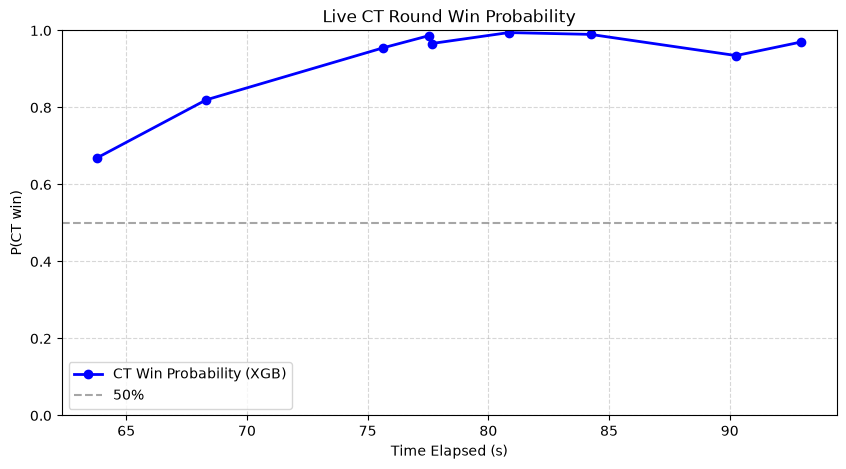

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(time_axis, ct_win_probs_xgb, "o-", color="blue", linewidth=2, label="CT Win Probability (XGB)")
#plt.plot(time_axis, ct_win_probs_logreg, "o-", color="red", linewidth=2, label="CT Win Probability (LogReg)")
#plt.plot(time_axis, ct_win_probs_mlp, "o-", color="green", linewidth=2, label="CT Win Probability (MLP)")
plt.axhline(0.5, color="gray", linestyle="--", alpha=0.7, label="50%")
plt.ylim(0.0, 1.0)
plt.xlabel("Time Elapsed (s)")
plt.ylabel("P(CT win)")
plt.title(f"Live CT Round Win Probability")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()